# Post-Exploitation Activity
In this notebook, we analyze the `input` table, which records the exact commands executed by attackers after successfully logging into the honeypots.

Our goals are to:
1. Identify the most common post-exploitation commands.
2. Compare the behavior of generic bots (Sensor 1) vs. IoT/Mirai bots (Sensor 2).
3. Extract the URLs and IP addresses used to download malware payloads.

#### 1. Setup and Data Merging
We merge the `input` and `sessions` dataframes and apply the date filter for the active window of sensors 1 and 2 (Jan 3 - Feb 1).

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Loading cached data...")
df_sessions = pd.read_pickle('../data/cache/sessions.pkl')
df_input = pd.read_pickle('../data/cache/input.pkl')
df_auth = pd.read_pickle('../data/cache/auth.pkl')

df_sessions['starttime'] = pd.to_datetime(df_sessions['starttime']) # Convert to pandas datetime

# Merge the auth table with the sessions table to get the 'sensor' and 'starttime' columns
# auth['session'] is the foreign key to sessions['id']
df_merged_input = pd.merge(
    df_input,
    df_sessions[['id', 'sensor', 'starttime']],
    left_on='session',
    right_on='id',
    how='inner'
)

# Apply the date filter for Sensors 1 and 2
start_date = '2026-01-03'
end_date = '2026-02-01'
mask = (df_merged_input['starttime'] >= start_date) & (df_merged_input['starttime'] <= end_date) & (df_merged_input['sensor'].astype(str).isin(['1', '2']))
df_filtered_input = df_merged_input.loc[mask].copy()

df_filtered_input['sensor'] = df_filtered_input['sensor'].astype(str) # force to string to avoid type error

print(f"Total commands executed in active window: {len(df_filtered_input):,}")

Loading cached data...
Total commands executed in active window: 13,397,852


#### 2. Top Executed Commands (Overall)
Automated scripts usually follow a set sequence of commands once they gain access. They typically check the system architecture, navigate to a writable directory (like `/tmp`), and attempt to download malware. Let's look at the top 15 most frequent commands across both sensors.

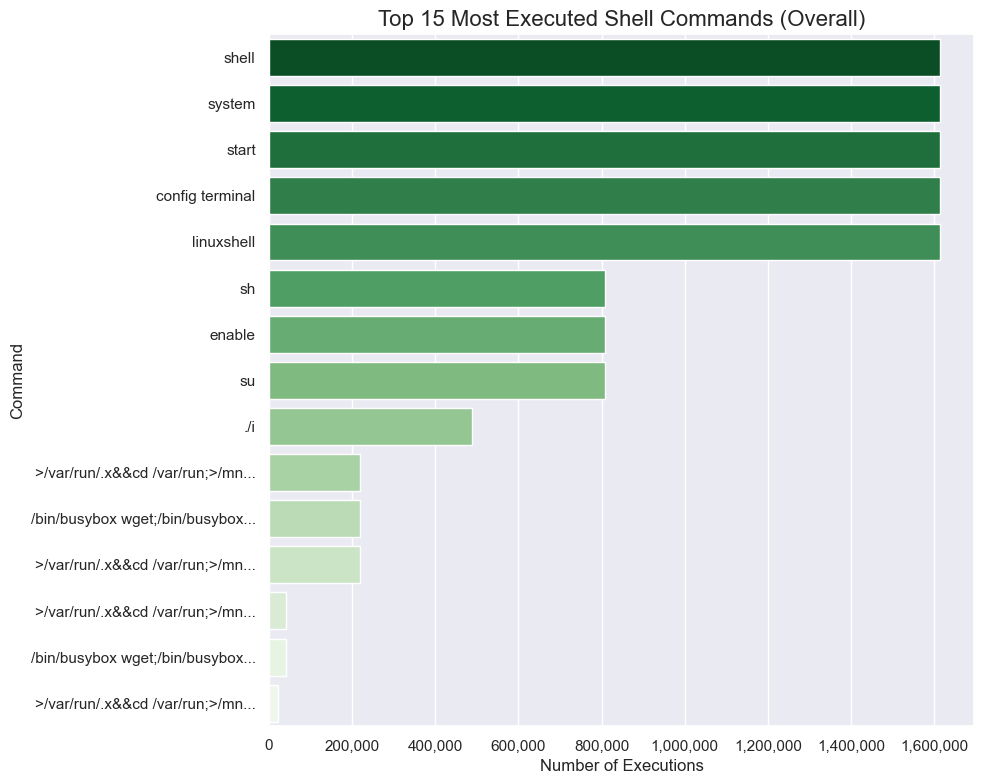

In [26]:
from matplotlib import ticker

# Get the top 15 commands
top_commands = df_filtered_input['input'].value_counts().head(15)

plt.figure(figsize=(10, 8))

# Plot graph
ax = sns.barplot(
    x=top_commands.values,
    y=top_commands.index,
    hue=top_commands.index,
    palette='Greens_r',
    legend=False
)

# set max length to 30 chars
clean_labels = [str(cmd)[:30] + '...' if len(str(cmd)) > 30 else str(cmd) for cmd in top_commands.index]

ax.set_yticks(range(len(clean_labels)))
ax.set_yticklabels(clean_labels)

ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}')) # remove scientific notation

plt.title('Top 15 Most Executed Shell Commands (Overall)', fontsize=16)
plt.xlabel('Number of Executions', fontsize=12)
plt.ylabel('Command', fontsize=12)
plt.tight_layout()
plt.show()

#### 3. Identical Execution Counts
When plotting the most executed commands, an interesting anomaly appears: the top 5 commands (`shell`, `system`, `start`, `config terminal`, and `linuxshell`) have almost identical execution counts.

This perfectly illustrates the behavior of automated IoT botnets. Many embedded devices (like routers and switches) do not drop a user into a standard Linux terminal (`/bin/sh`). Instead, they drop them into a restricted, custom configuration menu.

Because the botnet needs a real Linux shell to download and run its malware, its hardcoded script will fire every known "escape" command in sequence, hoping one of them breaks out of the menu. Because this is fully automated, the honeypot logs every single one of these commands identically.

We now look at the raw numbers to confirm this.

In [27]:
raw_counts = df_filtered_input['input'].value_counts().head(10) # Get counts of commands used

# Convert to dataframe
raw_counts_df = pd.DataFrame({
    'Command': raw_counts.index,
    'Execution Count': raw_counts.values
})

print("Raw Execution Counts (Notice the near-identical numbers at the top):")
display(raw_counts_df)

Raw Execution Counts (Notice the near-identical numbers at the top):


,Command,Execution Count
0,shell,1614676
1,system,1614674
2,start,1614560
3,config terminal,1614546
4,linuxshell,1614546
5,sh,807338
6,enable,807337
7,su,807264
8,./i,487965
9,>/var/run/.x&&cd /var/run;>/mnt/.x&&cd /mnt;>/...,219873


#### 4. Extracting Malware Server IPs
The primary goal of most honeypot breaches is to infect the host. Attackers achieve this by using utilities like `wget` or `curl` to download malware binaries from remote servers.

We will use Regular Expressions (Regex) to parse the raw command strings and extract any HTTP URLs or raw IP addresses that the attackers attempted to contact.

In [28]:
# Regex pattern to find IP addresses or http:// URLs
# It looks for sequences like: 192.168.1.1 or http://malware.com/payload.sh
payload_pattern = re.compile(r'(http://[^\s]+|\b(?:\d{1,3}\.){3}\d{1,3}\b)')

extracted_payloads = []

# Iterate through all the commands
for cmd in df_filtered_input['input'].dropna():
    if 'wget' in cmd or 'curl' in cmd or 'tftp' in cmd or 'http' in cmd: # look at commands that are downloading something
        matches = payload_pattern.findall(cmd)
        for match in matches:
            if '127.' not in match and '192.168.' not in match and '10.' not in match: # ignore local/loopback IPs
                extracted_payloads.append(match)

# Count occurrences of each server
payload_df = pd.Series(extracted_payloads).value_counts().reset_index()
payload_df.columns = ['Malware Server', 'Attempted Downloads']

print(f"Found {len(payload_df)} unique malicious servers/URLs.")
print("\nTop 15 Most Frequently Requested Payloads:")
display(payload_df.head(15))

Found 952 unique malicious servers/URLs.

Top 15 Most Frequently Requested Payloads:


,Malware Server,Attempted Downloads
0,http://61.53.85.143:35153/i,33656
1,http://119.164.12.224:40346/i,32330
2,http://27.200.87.165:47561/i,30546
3,http://175.169.107.17:48034/i,27862
4,http://113.237.6.20:50222/i,27198
5,http://61.168.162.82:54487/i,27030
6,http://39.71.227.180:42076/i,23688
7,http://61.53.85.143:35153/i;chmod,16828
8,http://222.137.153.230:48906/i,16778
9,http://182.121.111.243:35384/i,16638


#### 5. Command Analysis: Sensor 1 vs Sensor 2
In our previous analysis, we determined that Sensor 2 was breached by IoT-specific botnets (likely Mirai variants). Do the bots attacking sensor 2 type different commands than the generic bots breaching Sensor 1?

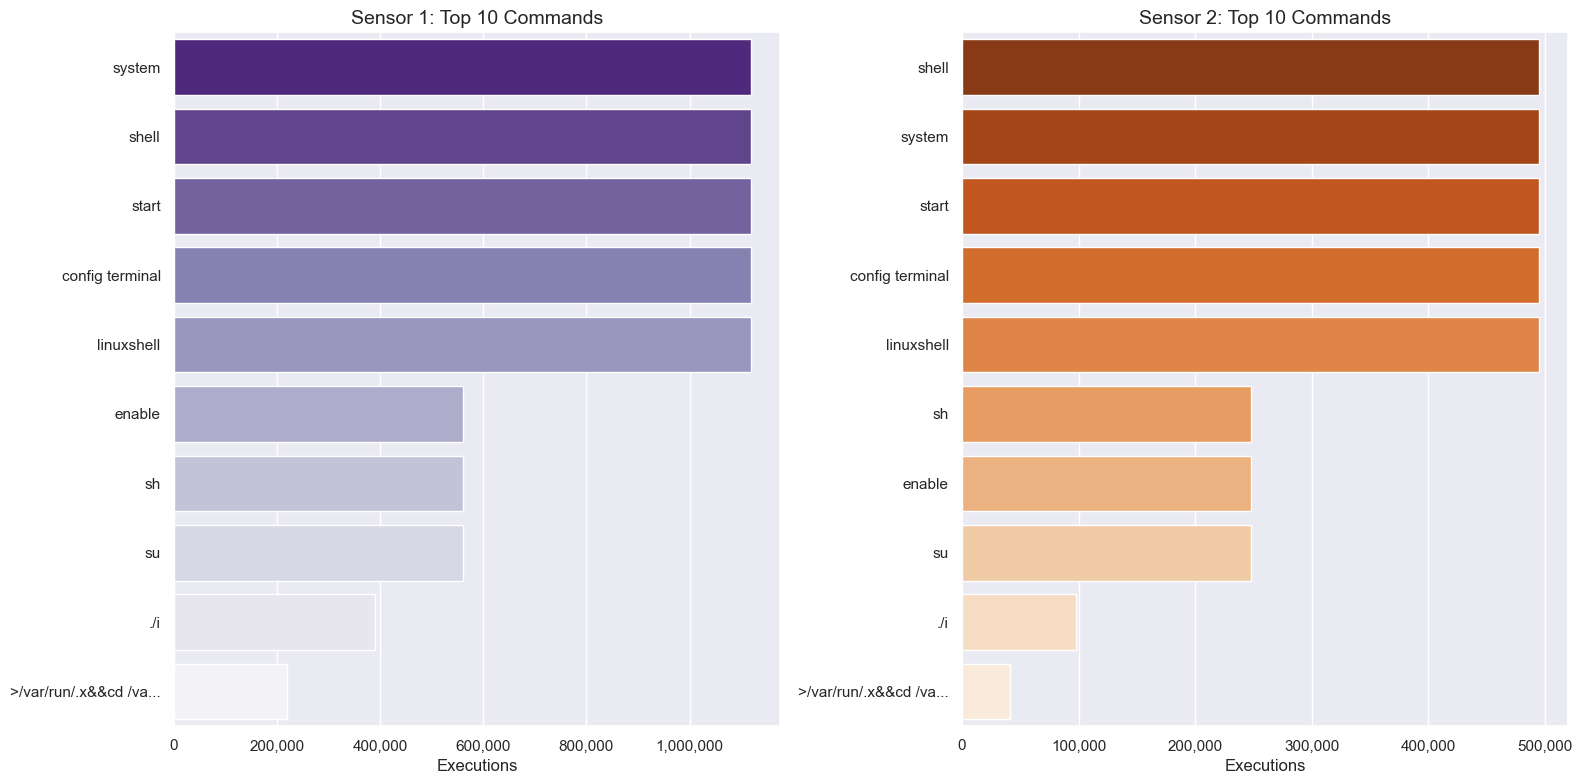

In [29]:
from matplotlib import ticker

# Separate the commands by sensor
s1_cmds = df_filtered_input[df_filtered_input['sensor'] == '1']['input'].value_counts().head(10)
s2_cmds = df_filtered_input[df_filtered_input['sensor'] == '2']['input'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot Sensor 1
sns.barplot(
    x=s1_cmds.values, y=s1_cmds.index,
    hue=s1_cmds.index, palette='Purples_r', legend=False, ax=axes[0]
)

s1_labels = [str(cmd)[:20] + '...' if len(str(cmd)) > 20 else str(cmd) for cmd in s1_cmds.index] # set max length to 20 chars
axes[0].set_yticks(range(len(s1_labels)))
axes[0].set_yticklabels(s1_labels)
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

axes[0].set_title('Sensor 1: Top 10 Commands', fontsize=14)
axes[0].set_xlabel('Executions')
axes[0].set_ylabel('')

# Plot Sensor 2
sns.barplot(
    x=s2_cmds.values, y=s2_cmds.index,
    hue=s2_cmds.index, palette='Oranges_r', legend=False, ax=axes[1]
)

s2_labels = [str(cmd)[:20] + '...' if len(str(cmd)) > 20 else str(cmd) for cmd in s2_cmds.index] # set max length to 20 chars
axes[1].set_yticks(range(len(s2_labels)))
axes[1].set_yticklabels(s2_labels)
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

axes[1].set_title('Sensor 2: Top 10 Commands', fontsize=14)
axes[1].set_xlabel('Executions')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

#### 6. Correlation: Login Credentials vs. Executed Commands
To fully map the attacker lifecycle, we must connect the infiltration phase to the post-exploitation phase.

To visualise this relationship, we will generate a correlation heatmap between the Top 5 most successful credentials and the Top 10 most executed commands.

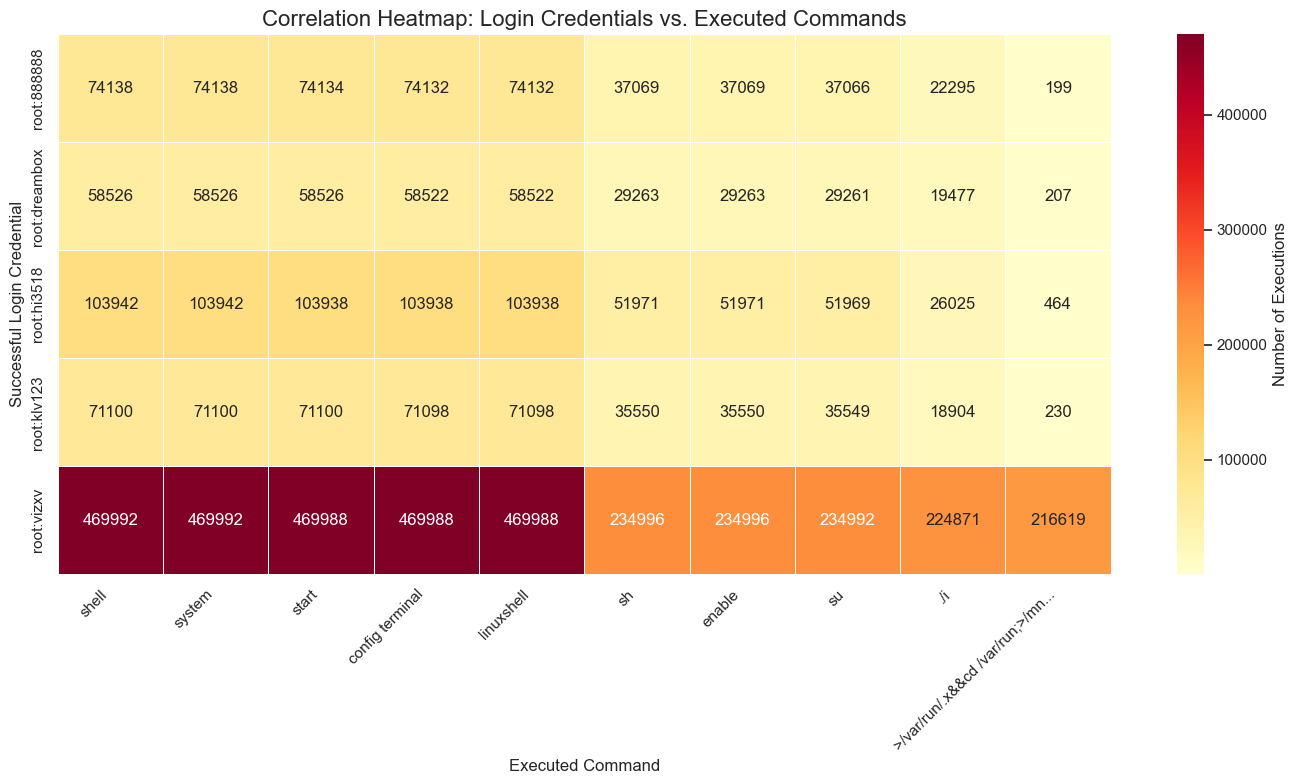

In [30]:
# Filter for successful logins and create the credentials column
successful_auth = df_auth[df_auth['success'].isin([1, '1', True])].copy()
successful_auth['credentials'] = successful_auth['username'] + ":" + successful_auth['password']

# 3. Merge successful logins with input
df_cred_cmd = pd.merge(
    successful_auth[['session', 'credentials']],
    df_filtered_input[['session', 'input']],
    on='session',
    how='inner'
)

# Identify the top 5 creds and top 10 commands (to keep matrix readable)
top_5_creds = df_cred_cmd['credentials'].value_counts().head(5).index
top_10_cmds = df_cred_cmd['input'].value_counts().head(10).index

# Filter the dataset to only include top combinations
heatmap_data = df_cred_cmd[
    (df_cred_cmd['credentials'].isin(top_5_creds)) &
    (df_cred_cmd['input'].isin(top_10_cmds))
]

# Create a matrix of counts
matrix = pd.crosstab(heatmap_data['credentials'], heatmap_data['input'])

# Sort the columns based on total frequency
matrix = matrix[top_10_cmds]

# Truncate command names to 30 characters so they fit
matrix.columns = [str(cmd)[:30] + '...' if len(str(cmd)) > 30 else str(cmd) for cmd in matrix.columns]

# Plot Heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(matrix, cmap='YlOrRd', annot=True, fmt='d', linewidths=.5, cbar_kws={'label': 'Number of Executions'}) # fmt='d' forces integers

plt.title('Correlation Heatmap: Login Credentials vs. Executed Commands', fontsize=16)
plt.xlabel('Executed Command', fontsize=12)
plt.ylabel('Successful Login Credential', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The correlation heatmap above provides additional data on how these IoT botnets operate.

1. **The Commands run were universal regardless of credentials:** While the absolute volume of successful breaches varies heavily by credential (with the `root:vizxv` Dahua camera vulnerability being the most exploited), the horizontal distribution of commands is proportionally identical across every single login vector. It does not matter which device the botnet thought it was hacking; once inside, it deployed the exact same script.

2. **Hardcoded Command Blocks:** Looking horizontally across any row, we can see that the first five commands (`shell`, `system`, `start`, `config terminal`, `linuxshell`) share near-identical execution counts. This confirms that these are not commands being typed sequentially based on feedback; rather, they are a single, hardcoded "escape block" fired simultaneously by the malware the moment authentication is successful.

#### 6. Conclusion
Comparing the post-exploitation commands of Sensor 1 and Sensor 2  reveals something interesting about modern automated threats. As shown by the graph and heatmap above, the command execution profiles for both sensors are nearly identical. While Sensor 1 experienced a higher absolute volume of executions, the *order* and *proportional frequency* of the commands (the identical `shell`, `system`, `start` escape sequence) are nearly identical across the top 10 commands of both honeypots.

Whether the botnet brute-forced a generic `root:admin` credential on Sensor 1 or a highly specific `root:xc3511` credential on Sensor 2, the resulting automated action was very homogenised. In the vast majority of cases, the malware assumes it has landed in a restricted embedded device menu, fires off a sequence of escape commands, and then attempts to pull down its payload from a remote drop server using `wget` or `curl`.

This suggests that even when non-IoT-specific credentials are used to gain
access to the honeypots, the attack scripts still appear to run commands that are designed to specifically
target IoT devices, suggesting that vulnerable IoT devices are the primary target of these automated
attacks. This also compounds earlier evidence that these adversaries are unintelligent and rigid, the credentials used to enter the honeypot seem to have no effect on the commands that are run upon entry.

#### Final Summary
Overall, the analysis provides a clear, start to finish look at how automated attacks operate in the wild. We tracked attack volumes over time, mapped the origins of the most aggressive IPs, and demonstrated how different botnets rely on specific password dictionaries to break in. By extracting the actual malware download links directly from the attackers' commands, we were able to map out their initial post-breach behavior - seeing the exact mechanisms these bots use to pull down their payloads as soon as they compromise a system.